In [1]:
from scipy.io import loadmat
import numpy as np
import pandas as pd
from pathlib import Path

In [2]:
DATA_DIR = Path("../data")

FILES = {
    # Normal
    "normal_0": "Normal_0.mat",
    "normal_1": "Normal_1.mat",
    "normal_2": "Normal_2.mat",
    "normal_3": "Normal_3.mat",

    # Inner race
    "inner_race_0": "IR007_0.mat",
    "inner_race_1": "IR007_1.mat",
    "inner_race_2": "IR007_2.mat",
    "inner_race_3": "IR007_3.mat",

    # Ball
    "ball_0": "B007_0.mat",
    "ball_1": "B007_1.mat",
    "ball_2": "B007_2.mat",
    "ball_3": "B007_3.mat",

    # Outer race
    "outer_race_0": "OR007@6_0.mat",
    "outer_race_1": "OR007@6_1.mat",
    "outer_race_2": "OR007@6_2.mat",
    "outer_race_3": "OR007@6_3.mat",
}

In [3]:
for name, filename in FILES.items():
    path = DATA_DIR / filename

    if path.exists():
        print(f"✓ {filename}")
    else:
        print(f"✗ MISSING: {filename}")

✓ Normal_0.mat
✓ Normal_1.mat
✓ Normal_2.mat
✓ Normal_3.mat
✓ IR007_0.mat
✓ IR007_1.mat
✓ IR007_2.mat
✓ IR007_3.mat
✓ B007_0.mat
✓ B007_1.mat
✓ B007_2.mat
✓ B007_3.mat
✓ OR007@6_0.mat
✓ OR007@6_1.mat
✓ OR007@6_2.mat
✓ OR007@6_3.mat


In [4]:
def load_bearing(path):
    data = loadmat(path)

    # Find Drive End vibration signal
    de_key = [k for k in data.keys() if k.endswith("_DE_time")][0]
    signal = data[de_key].flatten()

    # Find RPM
    rpm_keys = [k for k in data.keys() if k.endswith("RPM")]
    rpm = data[rpm_keys[0]].flatten()[0] if rpm_keys else None

    return signal, rpm


recordings = {}

for name, filename in FILES.items():
    signal, rpm = load_bearing(DATA_DIR / filename)

    recordings[name] = {
        "signal": signal,
        "rpm": rpm
    }

    print(f"{name:18s} | samples: {len(signal):7d} | RPM: {rpm}")

normal_0           | samples:  243938 | RPM: 1796
normal_1           | samples:  483903 | RPM: None
normal_2           | samples:  483903 | RPM: None
normal_3           | samples:  485643 | RPM: 1725
inner_race_0       | samples:  121265 | RPM: 1797
inner_race_1       | samples:  121991 | RPM: 1772
inner_race_2       | samples:  122136 | RPM: 1748
inner_race_3       | samples:  122917 | RPM: 1721
ball_0             | samples:  122571 | RPM: 1796
ball_1             | samples:  121410 | RPM: 1772
ball_2             | samples:  121556 | RPM: 1748
ball_3             | samples:  121556 | RPM: 1722
outer_race_0       | samples:  121991 | RPM: 1796
outer_race_1       | samples:  122426 | RPM: 1773
outer_race_2       | samples:  121410 | RPM: 1750
outer_race_3       | samples:  122571 | RPM: 1725


In [5]:
NORMAL_RPM = {
    0: 1796,
    1: 1772,
    2: 1748,
    3: 1725
}

for name, info in recordings.items():

    # Extract load from filename suffix
    load = int(name.split("_")[-1])

    # Use recorded RPM if available
    rpm = info["rpm"]

    # Fill missing normal RPM
    if rpm is None and name.startswith("normal"):
        rpm = NORMAL_RPM[load]

    info["load_hp"] = load
    info["rpm"] = rpm

    print(
        f"{name:18s} | "
        f"Load: {load} HP | "
        f"RPM: {rpm}"
    )

normal_0           | Load: 0 HP | RPM: 1796
normal_1           | Load: 1 HP | RPM: 1772
normal_2           | Load: 2 HP | RPM: 1748
normal_3           | Load: 3 HP | RPM: 1725
inner_race_0       | Load: 0 HP | RPM: 1797
inner_race_1       | Load: 1 HP | RPM: 1772
inner_race_2       | Load: 2 HP | RPM: 1748
inner_race_3       | Load: 3 HP | RPM: 1721
ball_0             | Load: 0 HP | RPM: 1796
ball_1             | Load: 1 HP | RPM: 1772
ball_2             | Load: 2 HP | RPM: 1748
ball_3             | Load: 3 HP | RPM: 1722
outer_race_0       | Load: 0 HP | RPM: 1796
outer_race_1       | Load: 1 HP | RPM: 1773
outer_race_2       | Load: 2 HP | RPM: 1750
outer_race_3       | Load: 3 HP | RPM: 1725


In [6]:
WINDOW_SIZE = 2048
MAX_SAMPLES = 40000

rows = []

for name, info in recordings.items():

    signal = info["signal"][:MAX_SAMPLES]

    # Get fault class
    label = name.rsplit("_", 1)[0]

    # Split signal into windows
    for start in range(0, len(signal) - WINDOW_SIZE + 1, WINDOW_SIZE):

        segment = signal[start:start + WINDOW_SIZE]

        rows.append({
            "recording": name,
            "label": label,
            "load_hp": info["load_hp"],
            "rpm": info["rpm"],
            "segment": segment
        })

print("Total windows:", len(rows))
print("Classes:")

pd.Series([row["label"] for row in rows]).value_counts()

Total windows: 304
Classes:


normal        76
inner_race    76
ball          76
outer_race    76
Name: count, dtype: int64

In [7]:
from scipy.stats import kurtosis, skew

def extract_time_features(segment):
    rms = np.sqrt(np.mean(segment ** 2))
    std = np.std(segment)
    peak = np.max(np.abs(segment))
    peak_to_peak = np.ptp(segment)

    crest_factor = peak / rms if rms != 0 else 0

    return {
        "rms": rms,
        "std": std,
        "kurtosis": kurtosis(segment, fisher=False),
        "skewness": skew(segment),
        "peak": peak,
        "peak_to_peak": peak_to_peak,
        "crest_factor": crest_factor
    }


feature_rows = []

for row in rows:
    features = extract_time_features(row["segment"])

    features["recording"] = row["recording"]
    features["label"] = row["label"]
    features["load_hp"] = row["load_hp"]
    features["rpm"] = row["rpm"]

    feature_rows.append(features)


features_df = pd.DataFrame(feature_rows)

print("Dataset shape:", features_df.shape)
features_df.head()

Dataset shape: (304, 11)


,rms,std,kurtosis,skewness,peak,peak_to_peak,crest_factor,recording,label,load_hp,rpm
0,0.073256,0.072266,2.954176,-0.137322,0.272869,0.490663,3.724845,normal_0,normal,0,1796
1,0.079035,0.077993,2.815420,-0.062348,0.226765,0.449775,2.869171,normal_0,normal,0,1796
2,0.074338,0.073370,2.778240,0.025960,0.219255,0.421403,2.949440,normal_0,normal,0,1796
3,0.073688,0.072967,2.930965,-0.147535,0.249295,0.496713,3.383105,normal_0,normal,0,1796
4,0.072112,0.071265,2.794399,-0.083451,0.224679,0.428287,3.115698,normal_0,normal,0,1796


In [8]:
SAMPLING_RATE = 12000

# CWRU drive-end bearing characteristic frequency multipliers
BPFI_FACTOR = 5.4152
BPFO_FACTOR = 3.5848
BSF_FACTOR = 4.7135
FTF_FACTOR = 0.39828


def extract_frequency_features(segment, rpm):
    # FFT
    fft_values = np.fft.rfft(segment)
    amplitude = np.abs(fft_values)
    frequencies = np.fft.rfftfreq(
        len(segment),
        d=1 / SAMPLING_RATE
    )

    # Ignore DC component
    amplitude[0] = 0

    dominant_frequency = frequencies[np.argmax(amplitude)]

    spectral_energy = np.sum(amplitude ** 2)

    # Shaft rotational frequency
    shaft_freq = rpm / 60

    # Bearing characteristic frequencies
    bpfi = BPFI_FACTOR * shaft_freq
    bpfo = BPFO_FACTOR * shaft_freq
    bsf = BSF_FACTOR * shaft_freq
    ftf = FTF_FACTOR * shaft_freq

    # Frequency resolution for a 2048-sample window
    resolution = SAMPLING_RATE / len(segment)

    # Use ± one FFT bin around theoretical frequency
    def band_energy(target):
        mask = np.abs(frequencies - target) <= resolution
        return np.sum(amplitude[mask])

    return {
        "dominant_frequency": dominant_frequency,
        "spectral_energy": spectral_energy,
        "bpfi_energy": band_energy(bpfi),
        "bpfo_energy": band_energy(bpfo),
        "bsf_energy": band_energy(bsf),
        "ftf_energy": band_energy(ftf)
    }

In [9]:
frequency_rows = []

for row in rows:
    features = extract_frequency_features(
        row["segment"],
        row["rpm"]
    )

    features["recording"] = row["recording"]
    features["label"] = row["label"]
    features["load_hp"] = row["load_hp"]
    features["rpm"] = row["rpm"]

    frequency_rows.append(features)


frequency_df = pd.DataFrame(frequency_rows)

print("Frequency dataset shape:", frequency_df.shape)
frequency_df.head()

Frequency dataset shape: (304, 10)


,dominant_frequency,spectral_energy,bpfi_energy,bpfo_energy,bsf_energy,ftf_energy,recording,label,load_hp,rpm
0,1037.109375,10952.144381,26.272346,20.904829,15.259251,1.468010,normal_0,normal,0,1796
1,1037.109375,12756.862158,41.731859,18.460359,24.026745,0.764191,normal_0,normal,0,1796
2,1037.109375,11289.154968,22.098138,17.575351,6.748192,1.535091,normal_0,normal,0,1796
3,1037.109375,11165.651093,26.105026,8.583130,14.745625,3.522547,normal_0,normal,0,1796
4,1037.109375,10650.929395,32.640562,10.304116,7.882559,2.682035,normal_0,normal,0,1796


In [10]:
# Remove duplicate metadata columns from frequency_df
frequency_features = frequency_df.drop(
    columns=["recording", "label", "load_hp", "rpm"]
)

# Combine time-domain and frequency-domain features
model_df = pd.concat(
    [
        features_df.reset_index(drop=True),
        frequency_features.reset_index(drop=True)
    ],
    axis=1
)

print("Final feature dataset shape:", model_df.shape)
print("\nColumns:")
print(model_df.columns.tolist())

print("\nClass distribution:")
print(model_df["label"].value_counts())

Final feature dataset shape: (304, 17)

Columns:
['rms', 'std', 'kurtosis', 'skewness', 'peak', 'peak_to_peak', 'crest_factor', 'recording', 'label', 'load_hp', 'rpm', 'dominant_frequency', 'spectral_energy', 'bpfi_energy', 'bpfo_energy', 'bsf_energy', 'ftf_energy']

Class distribution:
label
normal        76
inner_race    76
ball          76
outer_race    76
Name: count, dtype: int64


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Features used by the model
FEATURE_COLUMNS = [
    "rms",
    "std",
    "kurtosis",
    "skewness",
    "peak",
    "peak_to_peak",
    "crest_factor",
    "dominant_frequency",
    "spectral_energy",
    "bpfi_energy",
    "bpfo_energy",
    "bsf_energy",
    "ftf_energy"
]

# Train on 0, 1 and 2 HP
train_df = model_df[model_df["load_hp"] < 3].copy()

# Test only on 3 HP
test_df = model_df[model_df["load_hp"] == 3].copy()

X_train = train_df[FEATURE_COLUMNS]
y_train = train_df["label"]

X_test = test_df[FEATURE_COLUMNS]
y_test = test_df["label"]

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining classes:")
print(y_train.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())

Training samples: 228
Testing samples : 76

Training classes:
label
normal        57
inner_race    57
ball          57
outer_race    57
Name: count, dtype: int64

Testing classes:
label
normal        19
inner_race    19
ball          19
outer_race    19
Name: count, dtype: int64


In [12]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        random_state=42,
        n_jobs=-1
    )
}


results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results[name] = {
        "model": model,
        "predictions": predictions,
        "accuracy": accuracy
    }

    print("=" * 60)
    print(name)
    print("=" * 60)
    print(f"Accuracy: {accuracy:.3f}\n")
    print(classification_report(y_test, predictions))

Logistic Regression
Accuracy: 0.934

              precision    recall  f1-score   support

        ball       0.83      1.00      0.90        19
  inner_race       1.00      0.74      0.85        19
      normal       1.00      1.00      1.00        19
  outer_race       0.95      1.00      0.97        19

    accuracy                           0.93        76
   macro avg       0.94      0.93      0.93        76
weighted avg       0.94      0.93      0.93        76

Random Forest
Accuracy: 1.000

              precision    recall  f1-score   support

        ball       1.00      1.00      1.00        19
  inner_race       1.00      1.00      1.00        19
      normal       1.00      1.00      1.00        19
  outer_race       1.00      1.00      1.00        19

    accuracy                           1.00        76
   macro avg       1.00      1.00      1.00        76
weighted avg       1.00      1.00      1.00        76



In [13]:
import matplotlib.pyplot as plt

rf_model = results["Random Forest"]["model"]

importance = pd.Series(
    rf_model.feature_importances_,
    index=FEATURE_COLUMNS
).sort_values(ascending=False)

print(importance.round(4))

peak_to_peak          0.1488
peak                  0.1378
spectral_energy       0.1361
rms                   0.1338
std                   0.1287
kurtosis              0.1023
dominant_frequency    0.0898
bpfo_energy           0.0736
crest_factor          0.0239
skewness              0.0118
bpfi_energy           0.0052
bsf_energy            0.0043
ftf_energy            0.0039
dtype: float64


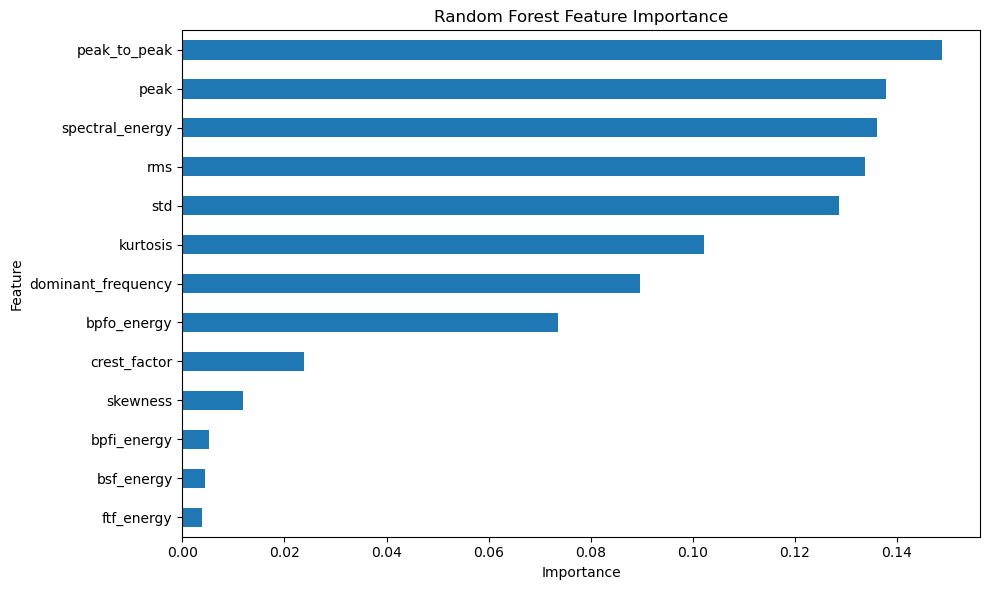

In [14]:
plt.figure(figsize=(10, 6))

importance.sort_values().plot(kind="barh")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

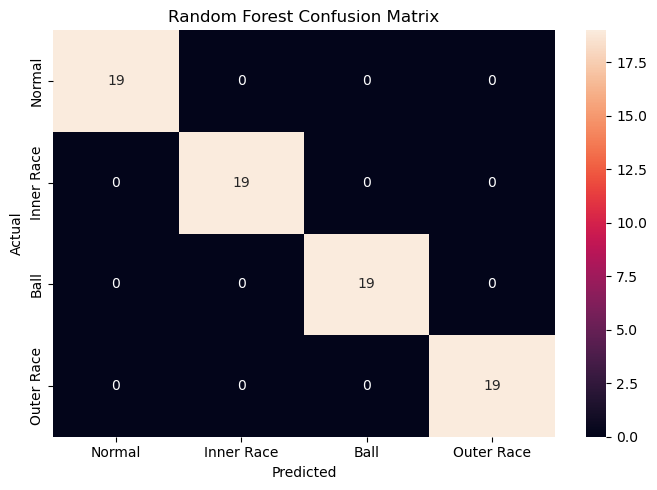

In [15]:
import seaborn as sns

rf_predictions = results["Random Forest"]["predictions"]

cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=["normal", "inner_race", "ball", "outer_race"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Normal", "Inner Race", "Ball", "Outer Race"],
    yticklabels=["Normal", "Inner Race", "Ball", "Outer Race"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [16]:
from scipy.signal import hilbert

def extract_envelope_features(segment, rpm):

    # Remove DC component
    signal = segment - np.mean(segment)

    # Analytic signal
    analytic_signal = hilbert(signal)

    # Envelope
    envelope = np.abs(analytic_signal)

    # Envelope spectrum
    envelope_fft = np.abs(np.fft.rfft(envelope))
    frequencies = np.fft.rfftfreq(
        len(envelope),
        d=1 / SAMPLING_RATE
    )

    envelope_fft[0] = 0

    shaft_freq = rpm / 60

    bpfi = BPFI_FACTOR * shaft_freq
    bpfo = BPFO_FACTOR * shaft_freq
    bsf = BSF_FACTOR * shaft_freq
    ftf = FTF_FACTOR * shaft_freq

    resolution = SAMPLING_RATE / len(segment)

    def envelope_band_energy(target):
        mask = np.abs(frequencies - target) <= resolution
        return np.sum(envelope_fft[mask])

    return {
        "env_bpfi": envelope_band_energy(bpfi),
        "env_bpfo": envelope_band_energy(bpfo),
        "env_bsf": envelope_band_energy(bsf),
        "env_ftf": envelope_band_energy(ftf)
    }

In [17]:
envelope_rows = []

for row in rows:

    features = extract_envelope_features(
        row["segment"],
        row["rpm"]
    )

    envelope_rows.append(features)

envelope_df = pd.DataFrame(envelope_rows)

print("Envelope features:", envelope_df.shape)
print(envelope_df.head())

Envelope features: (304, 4)
   env_bpfi  env_bpfo   env_bsf    env_ftf
0  6.425436  3.821683  4.933946   9.463387
1  2.050177  7.009942  2.986590   9.940609
2  5.634380  5.651380  5.603073  13.502560
3  5.176649  6.455845  4.341028  11.087502
4  4.232436  4.653969  3.039615  10.129308


In [18]:
envelope_features = envelope_df.reset_index(drop=True)

model_df_v2 = pd.concat(
    [
        model_df.reset_index(drop=True),
        envelope_features
    ],
    axis=1
)

print("Updated dataset shape:", model_df_v2.shape)
print(model_df_v2.columns.tolist())

Updated dataset shape: (304, 21)
['rms', 'std', 'kurtosis', 'skewness', 'peak', 'peak_to_peak', 'crest_factor', 'recording', 'label', 'load_hp', 'rpm', 'dominant_frequency', 'spectral_energy', 'bpfi_energy', 'bpfo_energy', 'bsf_energy', 'ftf_energy', 'env_bpfi', 'env_bpfo', 'env_bsf', 'env_ftf']


In [19]:
FEATURE_COLUMNS_V2 = FEATURE_COLUMNS + [
    "env_bpfi",
    "env_bpfo",
    "env_bsf",
    "env_ftf"
]

train_v2 = model_df_v2[model_df_v2["load_hp"] < 3]
test_v2 = model_df_v2[model_df_v2["load_hp"] == 3]

X_train_v2 = train_v2[FEATURE_COLUMNS_V2]
y_train_v2 = train_v2["label"]

X_test_v2 = test_v2[FEATURE_COLUMNS_V2]
y_test_v2 = test_v2["label"]


rf_v2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

rf_v2.fit(X_train_v2, y_train_v2)

predictions_v2 = rf_v2.predict(X_test_v2)

print("Random Forest with envelope features")
print("=" * 50)
print(f"Accuracy: {accuracy_score(y_test_v2, predictions_v2):.3f}")
print()
print(classification_report(y_test_v2, predictions_v2))

Random Forest with envelope features
Accuracy: 1.000

              precision    recall  f1-score   support

        ball       1.00      1.00      1.00        19
  inner_race       1.00      1.00      1.00        19
      normal       1.00      1.00      1.00        19
  outer_race       1.00      1.00      1.00        19

    accuracy                           1.00        76
   macro avg       1.00      1.00      1.00        76
weighted avg       1.00      1.00      1.00        76



In [20]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(
    rf_v2,
    MODEL_DIR / "bearing_fault_model.pkl"
)

print("Model saved successfully.")
print(MODEL_DIR / "bearing_fault_model.pkl")

Model saved successfully.
..\models\bearing_fault_model.pkl


In [21]:
joblib.dump(
    FEATURE_COLUMNS_V2,
    MODEL_DIR / "feature_columns.pkl"
)

print("Feature list saved successfully.")

Feature list saved successfully.


In [22]:
def predict_fault(segment, rpm):
    # Extract time-domain features
    time_features = extract_time_features(segment)

    # Extract frequency-domain features
    freq_features = extract_frequency_features(segment, rpm)

    # Extract envelope features
    env_features = extract_envelope_features(segment, rpm)

    # Combine everything
    features = {
        **time_features,
        **freq_features,
        **env_features
    }

    # Keep only features used by the model
    X = pd.DataFrame([features])[FEATURE_COLUMNS_V2]

    # Prediction
    prediction = rf_v2.predict(X)[0]

    # Class probabilities
    probabilities = rf_v2.predict_proba(X)[0]

    class_probabilities = dict(
        zip(rf_v2.classes_, probabilities)
    )

    confidence = max(probabilities)

    return {
        "prediction": prediction,
        "confidence": confidence,
        "probabilities": class_probabilities
    }

In [23]:
test_signal = recordings["outer_race_3"]["signal"]

test_segment = test_signal[:WINDOW_SIZE]

result = predict_fault(
    test_segment,
    recordings["outer_race_3"]["rpm"]
)

print("Prediction:", result["prediction"])
print("Confidence:", f"{result['confidence']:.2%}")

print("\nClass probabilities:")
for label, probability in result["probabilities"].items():
    print(f"{label:12s}: {probability:.2%}")

Prediction: outer_race
Confidence: 100.00%

Class probabilities:
ball        : 0.00%
inner_race  : 0.00%
normal      : 0.00%
outer_race  : 100.00%


In [24]:
for label in ["normal", "inner_race", "ball", "outer_race"]:

    signal = recordings[f"{label}_3"]["signal"]
    rpm = recordings[f"{label}_3"]["rpm"]

    segment = signal[:WINDOW_SIZE]

    result = predict_fault(segment, rpm)

    print("=" * 50)
    print(f"Actual: {label}")
    print(f"Predicted: {result['prediction']}")
    print(f"Confidence: {result['confidence']:.2%}")

    for cls, prob in result["probabilities"].items():
        print(f"  {cls:12s}: {prob:.2%}")

Actual: normal
Predicted: normal
Confidence: 94.00%
  ball        : 6.00%
  inner_race  : 0.00%
  normal      : 94.00%
  outer_race  : 0.00%
Actual: inner_race
Predicted: inner_race
Confidence: 98.50%
  ball        : 1.50%
  inner_race  : 98.50%
  normal      : 0.00%
  outer_race  : 0.00%
Actual: ball
Predicted: ball
Confidence: 96.00%
  ball        : 96.00%
  inner_race  : 1.50%
  normal      : 2.00%
  outer_race  : 0.50%
Actual: outer_race
Predicted: outer_race
Confidence: 100.00%
  ball        : 0.00%
  inner_race  : 0.00%
  normal      : 0.00%
  outer_race  : 100.00%


In [25]:
def predict_recording(signal, rpm, max_windows=10):

    predictions = []

    for start in range(
        0,
        min(len(signal), max_windows * WINDOW_SIZE),
        WINDOW_SIZE
    ):

        segment = signal[start:start + WINDOW_SIZE]

        if len(segment) < WINDOW_SIZE:
            break

        result = predict_fault(segment, rpm)

        predictions.append({
            "window": len(predictions) + 1,
            "prediction": result["prediction"],
            "confidence": result["confidence"]
        })

    return pd.DataFrame(predictions)

In [26]:
outer_signal = recordings["outer_race_3"]["signal"]
outer_rpm = recordings["outer_race_3"]["rpm"]

window_predictions = predict_recording(
    outer_signal,
    outer_rpm,
    max_windows=10
)

window_predictions

,window,prediction,confidence
0,1,outer_race,1.000
1,2,outer_race,0.925
2,3,outer_race,1.000
3,4,outer_race,1.000
4,5,outer_race,1.000
5,6,outer_race,1.000
6,7,outer_race,1.000
7,8,outer_race,1.000
8,9,outer_race,1.000
9,10,outer_race,1.000


In [27]:
def analyze_recording(signal, rpm, max_windows=10):

    predictions = predict_recording(
        signal,
        rpm,
        max_windows=max_windows
    )

    # Most common predicted class
    final_prediction = predictions["prediction"].mode()[0]

    # How consistently the windows agree
    consistency = (
        (predictions["prediction"] == final_prediction).mean()
    )

    # Average confidence
    average_confidence = predictions["confidence"].mean()

    if final_prediction == "normal":
        status = "HEALTHY"
        recommendation = "No immediate maintenance action required."
    else:
        status = "FAULT DETECTED"
        recommendation = (
            f"Inspect bearing for {final_prediction.replace('_', ' ')} fault."
        )

    return {
        "prediction": final_prediction,
        "average_confidence": average_confidence,
        "consistency": consistency,
        "windows_analyzed": len(predictions),
        "status": status,
        "recommendation": recommendation
    }

In [28]:
result = analyze_recording(
    recordings["outer_race_3"]["signal"],
    recordings["outer_race_3"]["rpm"]
)

result

{'prediction': 'outer_race',
 'average_confidence': np.float64(0.9925),
 'consistency': np.float64(1.0),
 'windows_analyzed': 10,
 'status': 'FAULT DETECTED',
 'recommendation': 'Inspect bearing for outer race fault.'}

In [30]:
import requests

signal = recordings["outer_race_3"]["signal"]
rpm = recordings["outer_race_3"]["rpm"]

payload = {
    "signal": signal[:WINDOW_SIZE].tolist(),
    "rpm": float(rpm)
}

response = requests.post(
    "http://127.0.0.1:8000/predict",
    json=payload
)

print("Status code:", response.status_code)
print(response.json())

Status code: 200
{'prediction': 'outer_race', 'confidence': 1.0, 'probabilities': {'ball': 0.0, 'inner_race': 0.0, 'normal': 0.0, 'outer_race': 1.0}, 'status': 'FAULT DETECTED', 'recommendation': 'Inspect bearing for outer race fault.'}
